# M12.3-S1 — Four-model paired G1 validation evaluation

Adapted from [M12.2 evaluation](M12_2_validation_evaluation.ipynb), preserving the M12.1/M12.2 metrics, train-only geometry, percentile and SNR bins. All cells are unexecuted; no historical outputs or conclusions are copied.

Compare M11 ordinary MSE, M12.1 global Mahalanobis weighted MSE (alpha=0.5), M12.2 marginal per-label weighted MSE (alpha=0.5), and M12.3-S1 marginal-mixture replacement sampling (p=0.35, peripheral q>=0.8) with ordinary MSE. Replacement sampling changes the effective training risk. This notebook reads saved validation predictions only; it neither trains nor predicts. No calibration, test or real-event evaluation or artifact writes.

Primary acceptance remains versus M11. Every M12 variant is compared to M11, and M12.3-S1 is also compared to both weighted variants. Exploratory central/peripheral and discordant-region findings cannot redefine success or establish causality from one checkpoint.


## 1. Inputs, provenance and immutable row alignment

Review the three recorded archive paths below; their existence is checked at runtime. Set `M12_3_VALIDATION_PATH` to the actual future archive, absolute or relative to `DATA_ROOT`. No future filename is assumed. `src.paths` resolves the existing data root (environment overrides config).

Required trusted NPZ fields: `pred_val`, `y_val` (standardized N×3), `idx_val` (original integer HDF5 row IDs), `y_mean`, `y_std`, `label_names`, `available_splits=['val']`, `checkpoint_file`, `dataset_path`, `split_path`, `label_stats_path`, `model_config`, `input_normalization`. Object metadata requires `allow_pickle=True`: use trusted project archives only. Embeddings are not read.

The inherited schema stores standardized predictions, converted exactly once using saved train scaling to [Msun, Msun, dimensionless]. Physical targets are checked against HDF5 validation labels. Physical-unit NPZ arrays masquerading as this standardized schema are incompatible; do not double-transform them. Prediction units rely on the trusted producer contract as well as scaler/target checks.

Each model is independently sorted by immutable row ID; require exactly 40,000 distinct validation IDs and identical standardized truth. Check config, checkpoint name, normalization, split/scaler hashes, label order, train references and model-specific provenance. These checks do not independently verify checkpoint bytes. Missing models or incompatible metadata stop evaluation.


In [1]:
from pathlib import Path
import sys, json, hashlib, copy
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open from the cbc_pe repository")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root, resolve_processed_artifact
from src.models.evaluate import regression_metrics, inverse_standardize
from src.models.sample_weighting import array_hash

CONFIG_PATHS = {"M11": ROOT / "configs/experiments/train_m11_final_G1_500k.json",
                "M12.1": ROOT / "configs/experiments/train_m12_1a_weighted_mse.json",
                "M12.2": ROOT / "configs/experiments/train_m12_2_marginal_alpha0p5.json",
                "M12.3-S1": ROOT / "configs/experiments/train_m12_3_S1_balanced_sampling.json"}
configs = {m:json.loads(p.read_text()) for m,p in CONFIG_PATHS.items()}
DATA_ROOT = resolve_data_root(config_data_root=configs["M11"].get("data_root"))
DATASET_ID = "M11_final_G1_500k"
LABELS = ["chirp_mass", "total_mass", "chi_eff"]
UNITS = ["Msun", "Msun", "dimensionless"]
MODELS = ["M11", "M12.1", "M12.2", "M12.3-S1"]
CANDIDATE = "M12.3-S1"
PAIRS = [(m,"M11") for m in MODELS[1:]] + [(CANDIDATE,"M12.1"),(CANDIDATE,"M12.2")]
PREFIX = {"M11":"M11", "M12.1":"M12_1", "M12.2":"M12_2", "M12.3-S1":"M12_3"}
REFERENCES = ["M11", "M12.1", "M12.2"]
RESULTS = DATA_ROOT / "results" / DATASET_ID

M12_1_VALIDATION_PATH = RESULTS / "m12_1_G1_val_predictions_embeddings.npz"
M12_2_VALIDATION_PATH = RESULTS / "m12_2_G1_val_predictions_embeddings.npz"  # Recorded in M12.2 evaluation; verify locally.
M12_3_VALIDATION_PATH = RESULTS / "m12_3_S1_G1_val_predictions_embeddings.npz"  # REQUIRED: actual future validation-only NPZ; no inference fallback.
BOOTSTRAP_COUNT = 400
BOOTSTRAP_SEED = 123
RUN_BOOTSTRAP = True  # Explicit manual opt-in; default replicate count remains 400.
MIN_COUNT = 30
MIN_2D_COUNT = 100
PERIPHERAL_MASS_MAX_DEGRADATION = 0.02  # Provisional, retained from the M12.2 evaluation configuration.
CHI_EFF_MAX_DEGRADATION = None  # RMSE fraction; decide prospectively, not after outcomes.
LOW_SNR_MAX_DEGRADATION = None  # RMSE fraction; decide prospectively, not after outcomes.

M11_VALIDATION_PATH = RESULTS / "m11_final_G1_500k_val_predictions_embeddings.npz"
CONTRACT_PATH = ROOT / "notebooks/m12/outputs/m12_0_baseline_contract.json"
PATHS = {key:resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
    file_name=configs["M11"]["dataset"][key], allow_legacy_flat=False)
    for key in ("dataset_file", "split_file", "label_stats_file")}

def require(ok, message):
    if not ok:
        raise ValueError(message)

def file_record(path, small=False):
    path = Path(path)
    require(path.is_file(), f"Missing frozen input: {path}; no generation fallback")
    st = path.stat()
    record = dict(path=str(path), size=st.st_size, mtime_ns=st.st_mtime_ns)
    if small:
        record["sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
    return record

require(M12_3_VALIDATION_PATH is not None, "Set M12_3_VALIDATION_PATH after validation predictions are available")
def resolve_prediction_path(value):
    path = Path(value).expanduser()
    return path if path.is_absolute() else DATA_ROOT / path
prediction_paths = {"M11":M11_VALIDATION_PATH,
    "M12.1":resolve_prediction_path(M12_1_VALIDATION_PATH),
    "M12.2":resolve_prediction_path(M12_2_VALIDATION_PATH),
    CANDIDATE:resolve_prediction_path(M12_3_VALIDATION_PATH)}
require(len({p.resolve() for p in prediction_paths.values()}) == 4, "Prediction paths must be distinct")
for model, method, tag in (("M12.1","train_label_mahalanobis","M12_1"),
                           ("M12.2","train_label_marginal","M12_2")):
    expected = copy.deepcopy(configs["M11"])
    expected.pop("data_root", None)
    expected["training"]["sample_weighting"] = dict(method=method, alpha=.5, normalization="train_mean_one")
    expected["outputs"] = configs[model]["outputs"]
    actual = copy.deepcopy(configs[model]); actual.pop("data_root",None)
    require(actual == expected, f"{model}: unexpected scientific config differences")
    require(configs[model]["outputs"]["checkpoint_tag"].startswith(tag), "Wrong checkpoint tag")
expected = copy.deepcopy(configs["M11"]); expected.pop("data_root",None)
expected["training"]["balanced_sampling"] = dict(enabled=True,mode="marginal_mixture",
    threshold=.8,p_peripheral=.35,seed=123)
expected["outputs"] = configs[CANDIDATE]["outputs"]
actual = copy.deepcopy(configs[CANDIDATE]); actual.pop("data_root",None)
require(actual == expected, "M12.3-S1 differs from M11 beyond sampling/output tag")
require(actual["outputs"]["checkpoint_tag"].startswith("M12_3_S1_"), "Wrong sampling checkpoint tag")
# Use geometry/definitions only; historical test metrics and real-event results are not evaluated.
frozen = json.loads(CONTRACT_PATH.read_text())
require(frozen["schema_version"] == 1 and frozen["dataset_id"] == DATASET_ID
        and frozen["labels"] == LABELS, "Wrong M12.0 contract")
# Pin the small split/scaler contracts as well as train geometry; do not trust filenames alone.
for key in ("split_file", "label_stats_file"):
    require(file_record(PATHS[key], True)["sha256"] ==
            frozen["provenance"]["local_artifacts"][key]["sha256"],
            f"Frozen M12.0 artifact content mismatch: {key}")
geometry = frozen["geometry"]
P_EDGES = np.asarray(geometry["edges"], dtype=float)
SNR_EDGES = np.asarray(frozen["definitions"]["snr_edges"], dtype=float)
require(np.array_equal(P_EDGES, [0,20,40,60,80,100]), "Changed percentile bins")
require(np.array_equal(SNR_EDGES, [10,12.5,15,17.5,20,22.5,25]), "Changed SNR bins")
del frozen
provenance = dict(contract=file_record(CONTRACT_PATH, True),
    configs={m:file_record(p, True) for m,p in CONFIG_PATHS.items()},
    artifacts={k:file_record(p, k != "dataset_file") for k,p in PATHS.items()},
    predictions={m:file_record(p) for m,p in prediction_paths.items()},
    split="val", units=dict(zip(LABELS, UNITS)))


In [2]:
with np.load(PATHS["split_file"], allow_pickle=False) as z:
    train_ids = np.sort(z["train_idx"].copy())
    val_ids = np.sort(z["val_idx"].copy())
    require(int(z["seed"].item()) == 123, "Split seed changed")
for name, ids, n in (("train",train_ids,400000), ("val",val_ids,40000)):
    require(ids.shape == (n,) and np.issubdtype(ids.dtype, np.integer)
            and len(np.unique(ids)) == n and ((ids >= 0) & (ids < 500000)).all(), f"Invalid {name} IDs")
require(np.intersect1d(train_ids, val_ids).size == 0, "Train/validation overlap")
require(array_hash(train_ids) == geometry["train_indices_sha256"], "Changed frozen train rows")
with np.load(PATHS["label_stats_file"], allow_pickle=False) as z:
    mean, std = z["y_mean"].copy(), z["y_std"].copy()
    require(z["label_names"].tolist() == LABELS, "Scaler label order")
    require(np.array_equal(np.sort(z["train_idx"]), train_ids), "Scaler train membership")
require(mean.shape == std.shape == (3,) and np.isfinite(mean).all()
        and np.isfinite(std).all() and (std > 0).all(), "Invalid saved scaler")

def load_validation(model):
    cfg = configs[model]
    checkpoint_name = (f"{DATASET_ID}_{cfg['model']['class_name']}_"
        f"{cfg['outputs']['checkpoint_tag']}_{cfg['training']['loss']}_seed123_checkpoint.pt")
    with np.load(prediction_paths[model], allow_pickle=True) as z:
        needed = {"pred_val", "y_val", "idx_val", "y_mean", "y_std", "label_names", "available_splits",
                  "checkpoint_file", "dataset_path", "split_path", "label_stats_path",
                  "model_config", "input_normalization"}
        require(needed <= set(z.files), f"{model}: missing {needed-set(z.files)}")
        require(z["available_splits"].tolist() == ["val"], "Require a validation-only prediction archive")
        require(z["label_names"].tolist() == LABELS, "Prediction label order")
        require(np.array_equal(z["y_mean"], mean) and np.array_equal(z["y_std"], std), "Scaler changed")
        saved = {k:z[k].item() for k in ("checkpoint_file", "dataset_path", "split_path",
                  "label_stats_path", "model_config", "input_normalization")}
        require(Path(saved["checkpoint_file"]).name == checkpoint_name, "Wrong recorded checkpoint")
        for key, local in (("dataset_path","dataset_file"), ("split_path","split_file"),
                           ("label_stats_path","label_stats_file")):
            require(Path(saved[key]).name == PATHS[local].name, "Recorded artifact mismatch")
        mc = saved["model_config"]
        require(mc["dataset_id"] == DATASET_ID and mc["label_names"] == LABELS, "Checkpoint dataset/labels")
        require(mc["class_name"] == cfg["model"]["class_name"]
                and mc["model_kwargs"] == cfg["model"]["kwargs"], "Checkpoint architecture changed")
        require(mc["training_seed"] == 123 and mc["split_seed"] == 123, "Checkpoint seeds changed")
        require(mc["train_size"] == 400000 and mc["val_size"] == 40000
                and mc["cal_size"] == 30000 and mc["test_size"] == 30000, "Checkpoint split sizes")
        require(saved["input_normalization"] == mc["input_normalization"] == cfg["input_normalization"],
                "Input normalization changed")
        if model in ("M12.1", "M12.2"):
            w = mc["sample_weighting"]
            for key, value in cfg["training"]["sample_weighting"].items():
                require(w[key] == value, f"Weight provenance: {key}")
            for key in ("train_indices_sha256", "n_train"):
                require(w[key] == geometry[key], f"Training reference differs from M12.0: {key}")
            if model == "M12.1":
                for key in ("reference_distance_sha256", "rank"):
                    require(w[key] == geometry[key], f"Global reference mismatch: {key}")
            else:
                require(w["label_names"] == LABELS and w["normalization_axis"] == "independent per label",
                        "Marginal label order/normalization changed")
                require(w["reduction"] == "mean(weight * squared_error) over batch and labels",
                        "Marginal reduction changed")
                for key in ("reference_distance_sha256", "normalized_weight_sha256_per_label"):
                    require(set(w[key]) == set(LABELS), f"Incomplete marginal hashes: {key}")
                # Numerical marginal reference/weight verification follows in section 4.
            require(w["validation_objective"] == "unweighted standardized MSELoss", "Weighted validation objective")
        if model == CANDIDATE:
            require(mc.get("sample_weighting") is None and mc["loss"] == "MSELoss",
                    "Sampling must use ordinary MSE without sample weighting")
            sampling = mc["balanced_sampling"]
            for key,value in dict(policy="M12.3-S1",mode="marginal_mixture",threshold=.8,
                                  p_peripheral=.35,seed=123,replacement=True,n_train=400000).items():
                require(sampling[key] == value, f"Sampling provenance mismatch: {key}")
            require(sampling["label_names"] == LABELS and
                    sampling["train_indices_sha256"] == geometry["train_indices_sha256"],
                    "Sampling labels/train rows mismatch")
            require(sampling["validation_objective"] == "unchanged unweighted standardized MSELoss",
                    "Sampling validation objective changed")
            require(sampling["seed_scheme"] ==
                    "SeedSequence([seed, 35, zero_based_epoch]); diagnostic S1 stream", "Sampling RNG contract")
        ids, truth_std, pred_std = (z[k].copy() for k in ("idx_val", "y_val", "pred_val"))
    require(ids.shape == val_ids.shape and np.issubdtype(ids.dtype, np.integer)
            and len(np.unique(ids)) == len(ids), "Duplicate or malformed prediction IDs")
    require(np.array_equal(np.sort(ids), val_ids), "Prediction archive does not cover exact validation membership")
    require(truth_std.shape == pred_std.shape == (len(ids),3)
            and np.isfinite(truth_std).all() and np.isfinite(pred_std).all(), "Invalid predictions/targets")
    # Reindex each archive independently by original row ID, never zip raw rows.
    order = np.argsort(ids)
    truth_std, pred_std = truth_std[order], pred_std[order]
    provenance["predictions"][model].update(saved=saved, ordered_ids_sha256=array_hash(val_ids),
        truth_sha256=array_hash(truth_std), prediction_sha256=array_hash(pred_std))
    return dict(truth_std=truth_std,
        truth=inverse_standardize(truth_std, mean, std).astype(np.float64),
        pred=inverse_standardize(pred_std, mean, std).astype(np.float64))

loaded = {m:load_validation(m) for m in MODELS}
for model in MODELS[1:]:
    require(np.array_equal(loaded["M11"]["truth_std"], loaded[model]["truth_std"]),
            f"Paired truth mismatch: {model}")
y_true = loaded["M11"]["truth"]
predictions = {m:loaded[m]["pred"] for m in MODELS}

def read_rows(dataset, ids):
    result = np.empty((len(ids), *dataset.shape[1:]), dtype=np.float64)
    for start in range(0, len(ids), 4096):
        result[start:start+4096] = dataset[ids[start:start+4096]]
    return result

snr, snr_issue = None, None
with h5py.File(PATHS["dataset_file"], "r") as h:
    require(h.attrs.get("experiment_id") == DATASET_ID
            and h.attrs.get("labels") == ",".join(LABELS), "HDF5 identity/labels")
    require(h["y"].shape == (500000,3), "Wrong G1 label dimensions")
    membership = h["split"].asstr()[:]
    require(np.array_equal(np.flatnonzero(membership == "train"), train_ids)
            and np.array_equal(np.flatnonzero(membership == "val"), val_ids), "HDF5 split membership")
    physical_val = read_rows(h["y"], val_ids)
    require(np.allclose(physical_val, y_true, rtol=2e-6, atol=2e-5), "Physical units/row pairing mismatch")
    train_y = read_rows(h["y"], train_ids)
    if ("final_network_snr" in h and h.attrs.get("snr_low_frequency_cutoff") == 30.
            and h.attrs.get("snr_high_frequency_cutoff") == 512.):
        require(h["final_network_snr"].shape == (500000,), "Wrong SNR shape")
        snr = read_rows(h["final_network_snr"], val_ids)
        require(np.isfinite(snr).all() and (snr >= 0).all(), "Invalid SNR")
    else:
        snr_issue = "final_network_snr or 30–512 Hz definition unavailable; no replacement allowed"
del physical_val, membership, loaded
require(np.isfinite(train_y).all() and np.isfinite(y_true).all()
        and all(np.isfinite(p).all() for p in predictions.values()), "Nonfinite physical arrays")
residuals = {m:p-y_true for m,p in predictions.items()}
provenance["ordered_val_ids_sha256"] = array_hash(val_ids)
provenance["snr_status"] = snr_issue or "verified final_network_snr, optimal 30–512 Hz"
display(pd.DataFrame([dict(model=m, n=len(val_ids), checkpoint=provenance["predictions"][m]["saved"]["checkpoint_file"],
    ids_sha256=provenance["ordered_val_ids_sha256"]) for m in MODELS]))
require(snr is not None, "Required frozen SNR metadata unavailable: " + str(snr_issue))


,model,n,checkpoint,ids_sha256
0,M11,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...
1,M12.1,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...
2,M12.2,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...
3,M12.3-S1,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...


## 2. Global metrics and focused plots

Reuse physical-unit RMSE, MAE, R² and signed residual bias; OLS fits prediction against truth with intercept. Tables contain all four models, plus explicit M12.2−M11 and M12.2−M12.1 deltas (negative favorable for errors/slope distance; positive favorable for R²). No cross-label score combines unlike units.

Retain the existing single 2×3 plot: deterministic ≤2000-row scatter subset, plus full-validation residual decile means and 16–84% residual spread. Spread is not a confidence interval. The only other figure is the exploratory mass-error versus spin-peripherality plot.

All deltas are candidate minus reference; negative RMSE/MAE/absolute-bias/slope-distance deltas favor the candidate, positive R2 deltas favor it. Signed bias/slope/intercept deltas have no universal favorable direction. Relative changes are delta/reference for nonnegative error metrics only; zero denominators are NaN.


,model,label,unit,n,RMSE,MAE,R2,bias,slope,intercept,slope_distance
0,M11,chirp_mass,Msun,40000,5.827355,3.949443,0.875498,0.078911,0.835143,6.239254,0.164857
1,M11,total_mass,Msun,40000,10.597668,7.543623,0.906696,0.379522,0.859322,13.720368,0.140678
2,M11,chi_eff,dimensionless,40000,0.194330,0.145279,0.804043,-0.005354,0.776008,-0.005369,0.223992
3,M12.1,chirp_mass,Msun,40000,5.797211,3.938447,0.876782,0.447505,0.852194,5.970662,0.147806
4,M12.1,total_mass,Msun,40000,10.490344,7.530605,0.908576,1.280246,0.879102,12.745321,0.120898
5,M12.1,chi_eff,dimensionless,40000,0.194161,0.145742,0.804383,-0.002470,0.780751,-0.002484,0.219249
6,M12.2,chirp_mass,Msun,40000,5.798379,3.837505,0.876733,0.059430,0.860804,5.260881,0.139196
7,M12.2,total_mass,Msun,40000,10.508600,7.446739,0.908258,0.718519,0.873951,12.672066,0.126049
8,M12.2,chi_eff,dimensionless,40000,0.195765,0.145379,0.801137,0.004016,0.784726,0.004003,0.215274
9,M12.3-S1,chirp_mass,Msun,40000,5.871472,3.930449,0.873605,0.086706,0.868840,4.987872,0.131160


,label,delta_RMSE,delta_MAE,delta_R2,delta_bias,delta_slope,delta_intercept,delta_slope_distance,relative_RMSE_change,relative_MAE_change,relative_slope_distance_change,comparison,candidate,reference
0,chirp_mass,-0.030144,-0.010996,0.001285,0.368594,0.017052,-0.268593,-0.017052,-0.005173,-0.002784,-0.103434,M12.1 minus M11,M12.1,M11
1,total_mass,-0.107324,-0.013018,0.001880,0.900724,0.019780,-0.975047,-0.019780,-0.010127,-0.001726,-0.140604,M12.1 minus M11,M12.1,M11
2,chi_eff,-0.000169,0.000463,0.000340,0.002885,0.004743,0.002885,-0.004743,-0.000867,0.003190,-0.021174,M12.1 minus M11,M12.1,M11
3,chirp_mass,-0.028976,-0.111939,0.001235,-0.019481,0.025661,-0.978373,-0.025661,-0.004972,-0.028343,-0.155656,M12.2 minus M11,M12.2,M11
4,total_mass,-0.089068,-0.096884,0.001562,0.338997,0.014629,-1.048302,-0.014629,-0.008405,-0.012843,-0.103989,M12.2 minus M11,M12.2,M11
5,chi_eff,0.001436,0.000100,-0.002906,0.009371,0.008718,0.009372,-0.008718,0.007387,0.000690,-0.038923,M12.2 minus M11,M12.2,M11
6,chirp_mass,0.044117,-0.018994,-0.001892,0.007795,0.033697,-1.251383,-0.033697,0.007571,-0.004809,-0.204401,M12.3-S1 minus M11,M12.3-S1,M11
7,total_mass,0.011547,-0.085687,-0.000203,-0.908515,0.039644,-4.668105,-0.039644,0.001090,-0.011359,-0.281811,M12.3-S1 minus M11,M12.3-S1,M11
8,chi_eff,0.003083,0.002646,-0.006267,0.013058,0.044191,0.013061,-0.044191,0.015865,0.018212,-0.197290,M12.3-S1 minus M11,M12.3-S1,M11
9,chirp_mass,0.074261,-0.007998,-0.003177,-0.360799,0.016645,-0.982790,-0.016645,0.012810,-0.002031,-0.112615,M12.3-S1 minus M12.1,M12.3-S1,M12.1


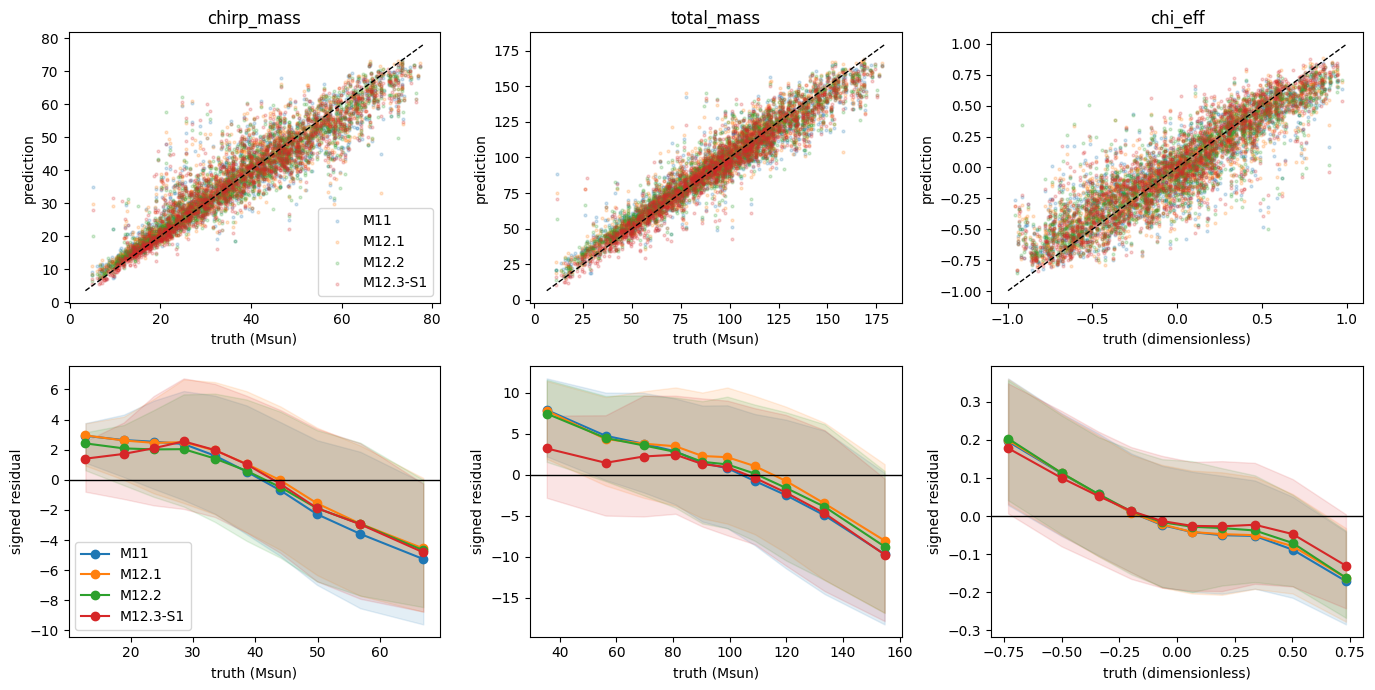

In [3]:
require((np.var(y_true, axis=0) > 0).all(), "OLS/R2 undefined for constant labels")
global_rows = []
for model, pred in predictions.items():
    table = regression_metrics(y_true, pred, LABELS, split_name="val").set_index("label")
    for j,label in enumerate(LABELS):
        slope, intercept = np.polyfit(y_true[:,j], pred[:,j], 1)
        global_rows.append(dict(model=model, label=label, unit=UNITS[j], n=len(val_ids),
            **table.loc[label, ["RMSE","MAE","R2","bias"]].to_dict(),
            slope=slope, intercept=intercept, slope_distance=abs(slope-1)))
global_metrics = pd.DataFrame(global_rows)
global_by_model = {m:global_metrics[global_metrics.model.eq(m)].set_index("label").reindex(LABELS)
                   for m in MODELS}
delta_tables = []
metrics = ["RMSE","MAE","R2","bias","slope","intercept","slope_distance"]
for candidate, ref in PAIRS:
    base = global_by_model[ref]
    delta = global_by_model[candidate][metrics]-base[metrics]
    delta.columns = ["delta_"+c for c in delta.columns]
    for metric in ("RMSE","MAE","slope_distance"):
        delta["relative_"+metric+"_change"] = np.where(base[metric] > 0,
            delta["delta_"+metric]/base[metric],np.nan)
    delta["comparison"] = candidate+" minus "+ref
    delta["candidate"], delta["reference"] = candidate, ref
    delta_tables.append(delta.reset_index())
global_delta = pd.concat(delta_tables,ignore_index=True)
display(global_metrics)
display(global_delta)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
chosen = np.linspace(0, len(val_ids)-1, min(2000,len(val_ids)), dtype=int)
for j,label in enumerate(LABELS):
    lo = min(y_true[:,j].min(), *(p[:,j].min() for p in predictions.values()))
    hi = max(y_true[:,j].max(), *(p[:,j].max() for p in predictions.values()))
    axes[0,j].plot([lo,hi], [lo,hi], "k--", linewidth=1)
    edges = np.unique(np.quantile(y_true[:,j], np.linspace(0,1,11)))
    groups = np.searchsorted(edges[1:-1], y_true[:,j], side="right")
    for model in MODELS:
        axes[0,j].scatter(y_true[chosen,j], predictions[model][chosen,j], s=4, alpha=.2, label=model)
        centers, means, lower, upper = [], [], [], []
        for b in range(len(edges)-1):
            mask = groups == b
            if mask.sum() >= MIN_COUNT:
                r = residuals[model][mask,j]
                centers.append(y_true[mask,j].mean()); means.append(r.mean())
                lower.append(np.quantile(r,.16)); upper.append(np.quantile(r,.84))
        line, = axes[1,j].plot(centers,means,"o-",label=model)
        axes[1,j].fill_between(centers,lower,upper,color=line.get_color(),alpha=.12)
    axes[0,j].set(title=label, xlabel=f"truth ({UNITS[j]})", ylabel="prediction")
    axes[1,j].axhline(0,color="black",linewidth=1)
    axes[1,j].set(xlabel=f"truth ({UNITS[j]})", ylabel="signed residual")
axes[0,0].legend(); axes[1,0].legend()
fig.tight_layout(); plt.show()


## 3. Q10/Q90 tails

Thresholds are linear quantiles of validation truth only. Lower ≤Q10 and upper ≥Q90 include ties; all models share these masks. Report signed bias, absolute bias, MAE and counts separately for both tails, plus both candidate-reference deltas. Quantiles are evaluation subset definitions, never training statistics. Do not cancel opposite tail signs.


In [4]:
thresholds = np.quantile(y_true,[.1,.9],axis=0)
tail_masks = {"lower":y_true <= thresholds[0],"upper":y_true >= thresholds[1]}
tail_rows = []
for j,label in enumerate(LABELS):
    for t,tail in enumerate(("lower","upper")):
        mask = tail_masks[tail][:,j]
        for model in MODELS:
            r = residuals[model][mask,j]
            tail_rows.append(dict(model=model,label=label,tail=tail,threshold=thresholds[t,j],
                n=int(mask.sum()),bias=r.mean(),abs_bias=abs(r.mean()),MAE=np.abs(r).mean()))
tails = pd.DataFrame(tail_rows)
tail_delta_rows = []
for candidate,ref in PAIRS:
    for label in LABELS:
        for tail in ("lower","upper"):
            subset = tails[tails.label.eq(label) & tails["tail"].eq(tail)].set_index("model")
            row = dict(candidate=candidate,reference=ref,comparison=candidate+" minus "+ref,
                       label=label,tail=tail,n=int(subset.loc[ref,"n"]))
            for metric in ("bias","abs_bias","MAE"):
                row["delta_"+metric] = subset.loc[candidate,metric]-subset.loc[ref,metric]
                if metric != "bias":
                    denom = subset.loc[ref,metric]
                    row["relative_"+metric+"_change"] = row["delta_"+metric]/denom if denom > 0 else np.nan
            tail_delta_rows.append(row)
tail_deltas = pd.DataFrame(tail_delta_rows)
display(tails); display(tail_deltas)
simultaneous_tails = tail_deltas[tail_deltas.candidate.eq(CANDIDATE)].pivot(
    index=["reference","label"],columns="tail",values="delta_abs_bias")
simultaneous_tails["both_tail_bias_magnitudes_improve_pointwise"] = (
    (simultaneous_tails.lower < 0) & (simultaneous_tails.upper < 0))
display(simultaneous_tails)  # Point directions only; inspect paired uncertainty below.


,model,label,tail,threshold,n,bias,abs_bias,MAE
0,M11,chirp_mass,lower,16.351124,4000,2.922491,2.922491,2.965636
1,M12.1,chirp_mass,lower,16.351124,4000,2.948652,2.948652,2.991768
2,M12.2,chirp_mass,lower,16.351124,4000,2.419627,2.419627,2.502264
3,M12.3-S1,chirp_mass,lower,16.351124,4000,1.405147,1.405147,2.036937
4,M11,chirp_mass,upper,61.013297,4000,-5.258440,5.258440,5.795812
5,M12.1,chirp_mass,upper,61.013297,4000,-4.556152,4.556152,5.208116
6,M12.2,chirp_mass,upper,61.013297,4000,-4.676870,4.676870,5.266705
7,M12.3-S1,chirp_mass,upper,61.013297,4000,-4.814316,4.814316,5.327314
8,M11,total_mass,lower,48.156340,4000,7.925503,7.925503,8.447998
9,M12.1,total_mass,lower,48.156340,4000,7.841341,7.841341,8.351668


,candidate,reference,comparison,label,tail,n,delta_bias,delta_abs_bias,relative_abs_bias_change,delta_MAE,relative_MAE_change
0,M12.1,M11,M12.1 minus M11,chirp_mass,lower,4000,0.026161,0.026161,0.008952,0.026133,0.008812
1,M12.1,M11,M12.1 minus M11,chirp_mass,upper,4000,0.702288,-0.702288,-0.133554,-0.587696,-0.101400
2,M12.1,M11,M12.1 minus M11,total_mass,lower,4000,-0.084162,-0.084162,-0.010619,-0.096329,-0.011403
3,M12.1,M11,M12.1 minus M11,total_mass,upper,4000,1.653633,-1.653633,-0.170836,-1.216351,-0.109858
4,M12.1,M11,M12.1 minus M11,chi_eff,lower,4000,0.003792,0.003792,0.019391,0.003720,0.018160
5,M12.1,M11,M12.1 minus M11,chi_eff,upper,4000,0.008996,-0.008996,-0.052661,-0.006399,-0.036089
6,M12.2,M11,M12.2 minus M11,chirp_mass,lower,4000,-0.502864,-0.502864,-0.172067,-0.463371,-0.156247
7,M12.2,M11,M12.2 minus M11,chirp_mass,upper,4000,0.581571,-0.581571,-0.110598,-0.529106,-0.091291
8,M12.2,M11,M12.2 minus M11,total_mass,lower,4000,-0.446682,-0.446682,-0.056360,-0.341221,-0.040391
9,M12.2,M11,M12.2 minus M11,total_mass,upper,4000,0.928430,-0.928430,-0.095916,-0.883763,-0.079819


tail                     lower     upper  \
reference label                            
M11       chi_eff    -0.017525 -0.040529   
          chirp_mass -1.517344 -0.444125   
          total_mass -4.696637  0.060232   
M12.1     chi_eff    -0.021317 -0.031533   
          chirp_mass -1.543505  0.258164   
          total_mass -4.612475  1.713865   
M12.2     chi_eff    -0.025282 -0.031450   
          chirp_mass -1.014480  0.137446   
          total_mass -4.249955  0.988662   

tail                  both_tail_bias_magnitudes_improve_pointwise  
reference label                                                    
M11       chi_eff                                            True  
          chirp_mass                                         True  
          total_mass                                        False  
M12.1     chi_eff                                            True  
          chirp_mass                                        False  
          total_mass                                        False  
M12.2     chi_eff                                            True  
          chirp_mass                                        False  
          total_mass                                        False

## 4. Global train-only Mahalanobis
Use M12.0's frozen μ, population σ, sample covariance and standardized-coordinate precision. Recompute train distances only to reconstruct its empirical CDF, and require the same sorted-distance hash. No evaluation covariance or percentile reference is fitted. Verify train moments/covariance against the saved contract before use. A numerical-library/hash discrepancy is an unresolved provenance issue; do not silently refit or relax it after seeing candidate results.

P(d) = 100 × fraction of train distances ≤ d (`searchsorted(..., side='right')`). Bins remain [0,20), [20,40), [40,60), [60,80), [80,100]. P80–P100 is peripheral. Counts need not be equal on validation. Conditional errors for n<30 are undefined, with counts retained. This is label-space Mahalanobis, not latent distance or marginal distance.

In [5]:
mu = np.asarray(geometry["mean"],dtype=float)
sigma = np.asarray(geometry["std_ddof0"],dtype=float)
precision = np.asarray(geometry["precision"],dtype=float)
require(mu.shape == sigma.shape == (3,) and precision.shape == (3,3)
        and np.isfinite(mu).all() and np.isfinite(sigma).all()
        and (sigma > 0).all() and np.isfinite(precision).all(), "Invalid frozen geometry")
np.testing.assert_allclose(train_y.mean(axis=0), mu, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(train_y.std(axis=0), sigma, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(np.cov(train_y,rowvar=False,ddof=1), geometry["covariance_ddof1"], rtol=1e-12, atol=1e-12)
def distance(values):
    z = (values-mu)/sigma
    squared = np.einsum("ni,ij,nj->n",z,precision,z)
    require(np.isfinite(squared).all() and (squared >= -1e-10).all(), "Invalid distance")
    return np.sqrt(np.maximum(squared,0))
reference_distances = np.sort(distance(train_y))
require(array_hash(reference_distances) == geometry["reference_distance_sha256"], "Train reference hash mismatch")
mahal_pct = 100*np.searchsorted(reference_distances,distance(y_true),side="right")/len(train_y)
require(np.isfinite(mahal_pct).all() and ((mahal_pct >= 0) & (mahal_pct <= 100)).all(), "Invalid percentiles")

def bin_masks(values, edges):
    return [(values >= lo) & ((values <= hi) if b == len(edges)-2 else (values < hi))
            for b,(lo,hi) in enumerate(zip(edges[:-1],edges[1:]))]

def compare_mask(mask, j, min_count=MIN_COUNT):
    n = int(mask.sum())
    row = dict(n=n, supported=n >= min_count)
    for model, prefix in PREFIX.items():
        r = residuals[model][mask,j]
        row[prefix+"_RMSE"] = float(np.sqrt(np.mean(r*r))) if n >= min_count else np.nan
        row[prefix+"_MAE"] = float(np.mean(np.abs(r))) if n >= min_count else np.nan
        row[prefix+"_bias"] = float(r.mean()) if n >= min_count else np.nan
        row[prefix+"_abs_bias"] = abs(row[prefix+"_bias"])
    for candidate,ref in PAIRS:
        cp, rp = PREFIX[candidate], PREFIX[ref]
        for metric in ("RMSE","MAE","bias","abs_bias"):
            change = row[cp+"_"+metric]-row[rp+"_"+metric]
            row[cp+"_delta_"+metric+"_vs_"+rp] = change
            if metric != "bias":
                denom = row[rp+"_"+metric]
                row[cp+"_relative_"+metric+"_change_vs_"+rp] = change/denom if denom > 0 else np.nan
            if candidate == CANDIDATE:  # Inherited acceptance-table aliases.
                row["delta_"+metric+"_vs_"+rp] = change
        row["relative_RMSE_change_vs_"+rp] = row["M12_3_relative_RMSE_change_vs_"+rp] if candidate == CANDIDATE else np.nan
    return row

def conditional(values, edges, dimension):
    masks = bin_masks(values,edges)
    return pd.DataFrame([dict(dimension=dimension, bin=b, lower=edges[b], upper=edges[b+1],
        upper_inclusive=b == len(edges)-2, label=label, **compare_mask(mask,j))
        for b,mask in enumerate(masks) for j,label in enumerate(LABELS)])

mahal_masks = bin_masks(mahal_pct,P_EDGES)
require((np.sum(mahal_masks,axis=0) == 1).all(), "Each validation row needs exactly one distance bin")
mahal_table = conditional(mahal_pct,P_EDGES,"global_mahalanobis_percentile")
require((mahal_table.groupby("label").n.sum().reindex(LABELS) == len(val_ids)).all(), "Incomplete distance counts")
peripheral = mahal_table[mahal_table.lower.eq(80)].set_index("label").reindex(LABELS)
display(mahal_table)
# Check candidate marginal provenance using only the same physical train labels.
# This does not change weights or refit any model.
from src.models.sample_weighting import marginal_label_weights
reproduced_weights, _, reproduced = marginal_label_weights(train_y,alpha=.5)
saved_marginal = provenance["predictions"]["M12.2"]["saved"]["model_config"]["sample_weighting"]
for key in ("reference_distance_sha256","normalized_weight_sha256",
            "normalized_weight_sha256_per_label","label_names","n_train"):
    require(reproduced[key] == saved_marginal[key], f"M12.2 marginal provenance mismatch: {key}")
for key in ("mean","std_ddof0","raw_weight_mean"):
    np.testing.assert_allclose(reproduced[key],saved_marginal[key],rtol=1e-12,atol=1e-12)
del reproduced_weights, _

sampling = provenance["predictions"][CANDIDATE]["saved"]["model_config"]["balanced_sampling"]
for key in ("mean","std_ddof0"):
    np.testing.assert_allclose(sampling["train_reference"][key],reproduced[key],rtol=1e-12,atol=1e-12)
require(sampling["train_reference"]["reference_distance_sha256"] == reproduced["reference_distance_sha256"],
        "Sampling marginal CDF references differ")
# Reproduce exact row probabilities from TRAIN labels only; no schedule/inference required.
train_q = np.column_stack([np.searchsorted(np.sort(np.abs((train_y[:,j]-mu[j])/sigma[j])),
    np.abs((train_y[:,j]-mu[j])/sigma[j]),side="right")/len(train_y) for j in range(3)])
probability = np.zeros(len(train_y),dtype=np.float64)
for j in range(3):
    for side in (False,True):
        pool = np.flatnonzero((train_q[:,j] >= .8) == side)
        require(len(pool) > 0,"Empty sampling pool")
        probability[pool] += (.35 if side else .65)/(3*len(pool))
require(array_hash(probability) == sampling["probabilities_sha256"], "Sampling probability hash mismatch")
del probability, train_q


,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,...,delta_RMSE_vs_M12_2,M12_3_delta_MAE_vs_M12_2,M12_3_relative_MAE_change_vs_M12_2,delta_MAE_vs_M12_2,M12_3_delta_bias_vs_M12_2,delta_bias_vs_M12_2,M12_3_delta_abs_bias_vs_M12_2,M12_3_relative_abs_bias_change_vs_M12_2,delta_abs_bias_vs_M12_2,relative_RMSE_change_vs_M12_2
0,global_mahalanobis_percentile,0,0.0,20.0,False,chirp_mass,8007,True,4.902952,3.623689,...,0.017456,0.115411,0.030925,0.115411,0.392657,0.392657,0.392657,6.787250,0.392657,0.003435
1,global_mahalanobis_percentile,0,0.0,20.0,False,total_mass,8007,True,8.630829,6.346546,...,0.288273,0.311477,0.047912,0.311477,-0.147392,-0.147392,-0.147392,-0.154904,-0.147392,0.032750
2,global_mahalanobis_percentile,0,0.0,20.0,False,chi_eff,8007,True,0.157579,0.121417,...,0.008540,0.006912,0.055561,0.006912,0.002069,0.002069,-0.002069,-0.315799,-0.002069,0.053081
3,global_mahalanobis_percentile,1,20.0,40.0,False,chirp_mass,7957,True,5.342037,3.842708,...,0.142804,0.206410,0.054236,0.206410,0.155437,0.155437,-0.155437,-0.628500,-0.155437,0.026580
4,global_mahalanobis_percentile,1,20.0,40.0,False,total_mass,7957,True,9.298274,6.800690,...,0.344546,0.375891,0.055385,0.375891,-0.817198,-0.817198,-0.623118,-0.865251,-0.623118,0.036948
5,global_mahalanobis_percentile,1,20.0,40.0,False,chi_eff,7957,True,0.167364,0.128352,...,0.008397,0.008893,0.068856,0.008893,0.004104,0.004104,0.004104,2.918234,0.004104,0.049498
6,global_mahalanobis_percentile,2,40.0,60.0,False,chirp_mass,8045,True,5.453683,3.817659,...,0.076538,0.078677,0.021464,0.078677,-0.058142,-0.058142,0.058142,0.208997,0.058142,0.014239
7,global_mahalanobis_percentile,2,40.0,60.0,False,total_mass,8045,True,9.758866,7.126635,...,0.102718,0.020360,0.002924,0.020360,-1.368948,-1.368948,0.129805,0.209507,0.129805,0.010696
8,global_mahalanobis_percentile,2,40.0,60.0,False,chi_eff,8045,True,0.180632,0.136712,...,0.004255,0.004276,0.031367,0.004276,0.001700,0.001700,0.001700,0.378388,0.001700,0.023400
9,global_mahalanobis_percentile,3,60.0,80.0,False,chirp_mass,7952,True,5.982311,3.973223,...,0.079623,0.048305,0.013013,0.048305,-0.098263,-0.098263,0.098263,0.227671,0.098263,0.013807


## 5. Network SNR
Use only the saved `final_network_snr`: synthetic optimal final network SNR, 30–512 Hz, with M12.0 edges [10,12.5,15,17.5,20,22.5,25]. No catalog, requested, or recomputed SNR substitution. Nominal bins are left inclusive and final upper inclusive. Explicit under/overflow rows ensure every validation row is accounted for; all remain in global metrics. Low SNR below denotes [10,12.5), with out-of-range values reported separately. Global differences are in section 2; this table exposes their SNR dependence.

In [6]:
snr_table = pd.DataFrame()
low_snr = pd.DataFrame()
if snr is None:
    print("UNRESOLVED SNR:", snr_issue)
else:
    snr_table = conditional(snr,SNR_EDGES,"final_network_snr")
    outside = pd.DataFrame([dict(dimension="final_network_snr",bin=name, label=label,
        **compare_mask(mask,j)) for name,mask in (("below_10",snr < 10),("above_25",snr > 25))
        for j,label in enumerate(LABELS)])
    snr_table = pd.concat([snr_table,outside],ignore_index=True)
    require((snr_table.groupby("label").n.sum().reindex(LABELS) == len(val_ids)).all(), "Incomplete SNR counts")
    low_snr = snr_table[snr_table.bin.eq(0)].set_index("label").reindex(LABELS)
    display(snr_table)

,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,...,delta_RMSE_vs_M12_2,M12_3_delta_MAE_vs_M12_2,M12_3_relative_MAE_change_vs_M12_2,delta_MAE_vs_M12_2,M12_3_delta_bias_vs_M12_2,delta_bias_vs_M12_2,M12_3_delta_abs_bias_vs_M12_2,M12_3_relative_abs_bias_change_vs_M12_2,delta_abs_bias_vs_M12_2,relative_RMSE_change_vs_M12_2
0,final_network_snr,0,10.0,12.5,False,chirp_mass,6757,True,7.949685,5.582626,...,0.029322,0.120519,0.022085,0.120519,0.154012,0.154012,0.154012,3.402829,0.154012,0.003724
1,final_network_snr,0,10.0,12.5,False,total_mass,6757,True,14.979980,10.979815,...,0.123144,0.035185,0.003226,0.035185,-1.565418,-1.565418,-1.057008,-0.806130,-1.057008,0.008305
2,final_network_snr,0,10.0,12.5,False,chi_eff,6757,True,0.261345,0.203745,...,0.000104,0.001399,0.006815,0.001399,-0.007634,-0.007634,-0.007634,-0.774957,-0.007634,0.000390
3,final_network_snr,1,12.5,15.0,False,chirp_mass,6711,True,6.848787,4.743865,...,0.027654,0.057972,0.012560,0.057972,0.030090,0.030090,0.030090,0.144711,0.030090,0.004066
4,final_network_snr,1,12.5,15.0,False,total_mass,6711,True,12.570757,8.978671,...,-0.050654,-0.067274,-0.007551,-0.067274,-1.317780,-1.317780,-0.491691,-0.543464,-0.491691,-0.004065
5,final_network_snr,1,12.5,15.0,False,chi_eff,6711,True,0.225583,0.171863,...,-0.000526,0.000848,0.004899,0.000848,0.001128,0.001128,0.001128,0.196648,0.001128,-0.002313
6,final_network_snr,2,15.0,17.5,False,chirp_mass,6636,True,5.742407,3.955851,...,0.136593,0.094744,0.024587,0.094744,-0.013852,-0.013852,-0.013852,-0.344201,-0.013852,0.023788
7,final_network_snr,2,15.0,17.5,False,total_mass,6636,True,10.025744,7.459881,...,0.155024,0.039815,0.005403,0.039815,-1.283995,-1.283995,0.184009,0.334565,0.184009,0.015399
8,final_network_snr,2,15.0,17.5,False,chi_eff,6636,True,0.192272,0.145999,...,0.002832,0.002160,0.014811,0.002160,0.005113,0.005113,0.005113,1.704079,0.005113,0.014747
9,final_network_snr,3,17.5,20.0,False,chirp_mass,6625,True,4.924411,3.425289,...,0.096461,0.092974,0.027835,0.092974,-0.006299,-0.006299,-0.006299,-0.148971,-0.006299,0.019522


## 6. Exploratory marginal and cross-label diagnostics

Reuse |y_k−μ_train,k|/σ_train,k and the per-label right-side train empirical CDF, with unchanged [0,20,40,60,80,100] percentile edges. Absolute distances merge upper/lower extremes; section 3 retains their signs. No validation statistics fit a training reference. Show each label's error versus its own peripherality, and all cross-label relations, especially mass error versus chi_eff peripherality.

Retain at most two coarse mass-P80 × spin-P80 tables, only when all four cells have ≥100 rows. False means <P80, not central. Marginal/cross-label patterns are descriptive associations, not causal evidence of shared-task gradient conflict. These exploratory tables do not override primary acceptance or justify retroactive weight tuning.


,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,...,M12_3_delta_MAE_vs_M12_2,M12_3_relative_MAE_change_vs_M12_2,delta_MAE_vs_M12_2,M12_3_delta_bias_vs_M12_2,delta_bias_vs_M12_2,M12_3_delta_abs_bias_vs_M12_2,M12_3_relative_abs_bias_change_vs_M12_2,delta_abs_bias_vs_M12_2,relative_RMSE_change_vs_M12_2,reference_label
0,chirp_mass,0,0.0,20.0,False,chirp_mass,7912,True,5.095718,3.642738,...,0.014053,0.003554,0.014053,0.458525,0.458525,0.458525,0.580369,0.458525,-0.001171,chirp_mass
3,chirp_mass,1,20.0,40.0,False,chirp_mass,7928,True,5.449723,3.830882,...,0.209441,0.053197,0.209441,0.355245,0.355245,0.355245,0.536265,0.355245,0.026346,chirp_mass
6,chirp_mass,2,40.0,60.0,False,chirp_mass,8165,True,5.651507,3.863706,...,0.310383,0.082979,0.310383,0.108774,0.108774,0.108774,0.352044,0.108774,0.044050,chirp_mass
9,chirp_mass,3,60.0,80.0,False,chirp_mass,8074,True,5.849986,3.812921,...,0.117877,0.034017,0.117877,-0.235267,-0.235267,-0.149541,-0.777223,-0.149541,0.028397,chirp_mass
12,chirp_mass,4,80.0,100.0,True,chirp_mass,7921,True,6.929244,4.602003,...,-0.194401,-0.047406,-0.194401,-0.548136,-0.548136,0.548136,0.328877,0.548136,-0.026366,chirp_mass
16,total_mass,0,0.0,20.0,False,total_mass,7969,True,9.160533,6.511800,...,0.284509,0.041095,0.284509,-0.303166,-0.303166,-0.303166,-0.213514,-0.303166,0.029525,total_mass
19,total_mass,1,20.0,40.0,False,total_mass,7961,True,9.253008,6.633318,...,0.305615,0.045081,0.305615,-0.439751,-0.439751,-0.439751,-0.300050,-0.439751,0.044891,total_mass
22,total_mass,2,40.0,60.0,False,total_mass,8004,True,9.517805,7.085091,...,0.416138,0.059432,0.416138,-0.939026,-0.939026,-0.939026,-0.945676,-0.939026,0.039957,total_mass
25,total_mass,3,60.0,80.0,False,total_mass,8127,True,10.383890,7.722701,...,-0.024040,-0.003256,-0.024040,-1.927592,-1.927592,1.164343,3.051018,1.164343,0.020856,total_mass
28,total_mass,4,80.0,100.0,True,total_mass,7939,True,13.930931,9.771142,...,-0.930567,-0.101645,-0.930567,-2.620251,-2.620251,2.620251,3.931572,2.620251,-0.043847,total_mass


,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,...,M12_3_delta_MAE_vs_M12_2,M12_3_relative_MAE_change_vs_M12_2,delta_MAE_vs_M12_2,M12_3_delta_bias_vs_M12_2,delta_bias_vs_M12_2,M12_3_delta_abs_bias_vs_M12_2,M12_3_relative_abs_bias_change_vs_M12_2,delta_abs_bias_vs_M12_2,relative_RMSE_change_vs_M12_2,reference_label
1,chirp_mass,0,0.0,20.0,False,total_mass,7912,True,8.487750,6.188167,...,0.146441,0.022344,0.146441,-0.168351,-0.168351,-0.168351,-0.082171,-0.168351,0.013752,chirp_mass
2,chirp_mass,0,0.0,20.0,False,chi_eff,7912,True,0.170752,0.130116,...,-0.003048,-0.022642,-0.003048,0.006139,0.006139,0.006139,0.920659,0.006139,-0.019161,chirp_mass
4,chirp_mass,1,20.0,40.0,False,total_mass,7928,True,9.033148,6.581467,...,0.155984,0.023164,0.155984,-0.445975,-0.445975,-0.445975,-0.232182,-0.445975,0.015514,chirp_mass
5,chirp_mass,1,20.0,40.0,False,chi_eff,7928,True,0.172705,0.132812,...,0.001182,0.008711,0.001182,0.007892,0.007892,0.007892,0.820480,0.007892,0.009422,chirp_mass
7,chirp_mass,2,40.0,60.0,False,total_mass,8165,True,9.767927,7.239747,...,0.061446,0.008672,0.061446,-1.081984,-1.081984,-1.081984,-0.781425,-1.081984,0.016046,chirp_mass
8,chirp_mass,2,40.0,60.0,False,chi_eff,8165,True,0.183597,0.138740,...,0.006519,0.047192,0.006519,0.005803,0.005803,0.005803,0.400548,0.005803,0.037476,chirp_mass
10,chirp_mass,3,60.0,80.0,False,total_mass,8074,True,10.587431,7.848113,...,-0.091264,-0.012035,-0.091264,-2.114292,-2.114292,0.528999,0.667384,0.528999,0.019134,chirp_mass
11,chirp_mass,3,60.0,80.0,False,chi_eff,8074,True,0.197078,0.147099,...,0.006808,0.047508,0.006808,-0.001940,-0.001940,-0.001940,-0.153719,-0.001940,0.030886,chirp_mass
13,chirp_mass,4,80.0,100.0,True,total_mass,7921,True,14.174385,9.863410,...,-0.216166,-0.023282,-0.216166,-2.414795,-2.414795,2.414795,0.937510,2.414795,-0.004449,chirp_mass
14,chirp_mass,4,80.0,100.0,True,chi_eff,7921,True,0.239565,0.177786,...,0.001057,0.006026,0.001057,0.000587,0.000587,-0.000587,-0.024646,-0.000587,-0.010469,chirp_mass


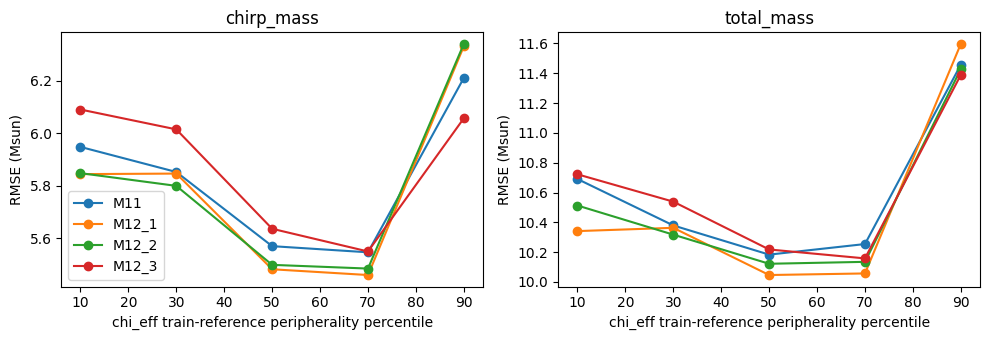

,label,mass_P80,chi_eff_P80,n
0,chirp_mass,False,False,25682
1,chirp_mass,False,True,6397
2,chirp_mass,True,False,6480
3,chirp_mass,True,True,1441
4,total_mass,False,False,25594
5,total_mass,False,True,6467
6,total_mass,True,False,6568
7,total_mass,True,True,1371


,label,mass_P80,chi_eff_P80,n,supported,M11_RMSE,M11_MAE,M11_bias,M11_abs_bias,M12_1_RMSE,...,delta_RMSE_vs_M12_2,M12_3_delta_MAE_vs_M12_2,M12_3_relative_MAE_change_vs_M12_2,delta_MAE_vs_M12_2,M12_3_delta_bias_vs_M12_2,delta_bias_vs_M12_2,M12_3_delta_abs_bias_vs_M12_2,M12_3_relative_abs_bias_change_vs_M12_2,delta_abs_bias_vs_M12_2,relative_RMSE_change_vs_M12_2
0,chirp_mass,False,False,25682,True,5.387912,3.739828,0.531643,0.531643,5.487843,...,0.256495,0.245717,0.066602,0.245717,0.229524,0.229524,0.229524,0.487619,0.229524,0.047149
1,chirp_mass,False,True,6397,True,6.028209,3.982961,0.619087,0.619087,6.256405,...,-0.279458,-0.164585,-0.040079,-0.164585,-0.072193,-0.072193,-0.072193,-0.132311,-0.072193,-0.044317
2,chirp_mass,True,False,6480,True,6.921231,4.638316,-1.952692,1.952692,6.292859,...,-0.140841,-0.209959,-0.050583,-0.209959,-0.561613,-0.561613,0.561613,0.317728,0.561613,-0.021833
3,chirp_mass,True,True,1441,True,6.965160,4.438711,-1.251956,1.251956,6.656671,...,-0.303511,-0.124441,-0.032106,-0.124441,-0.487530,-0.487530,0.487530,0.401934,0.487530,-0.046732
4,total_mass,False,False,25594,True,9.267604,6.763812,0.637071,0.637071,9.380108,...,0.371440,0.322125,0.047441,0.322125,-0.788444,-0.788444,-0.788444,-0.741400,-0.788444,0.039722
5,total_mass,False,True,6467,True,10.793940,7.895286,0.947593,0.947593,11.136705,...,0.162144,-0.063215,-0.007953,-0.063215,-1.379134,-1.379134,-0.728119,-0.691060,-0.728119,0.014719
6,total_mass,True,False,6568,True,13.879541,9.705829,-1.120744,1.120744,12.916832,...,-0.523445,-0.857725,-0.094089,-0.857725,-2.642823,-2.642823,2.642823,3.055458,2.642823,-0.039463
7,total_mass,True,True,1371,True,14.174539,10.084035,0.079249,0.079249,13.559051,...,-0.862561,-1.279530,-0.136969,-1.279530,-2.512116,-2.512116,1.943270,6.832328,1.943270,-0.065344


In [7]:
marginal_pct = np.empty_like(y_true)
marginal_reference_hashes = {}
for j,label in enumerate(LABELS):
    reference = np.sort(np.abs((train_y[:,j]-mu[j])/sigma[j]))
    query = np.abs((y_true[:,j]-mu[j])/sigma[j])
    marginal_pct[:,j] = 100*np.searchsorted(reference,query,side="right")/len(reference)
    marginal_reference_hashes[label] = array_hash(reference)
    require(marginal_reference_hashes[label] == saved_marginal["reference_distance_sha256"][label],
            f"Marginal diagnostic reference mismatch: {label}")
require(np.isfinite(marginal_pct).all() and ((marginal_pct >= 0) & (marginal_pct <= 100)).all(), "Marginal percentile bounds")
for j in range(3):
    require((np.sum(bin_masks(marginal_pct[:,j],P_EDGES),axis=0) == 1).all(), "Marginal bin assignment")
marginal_table = pd.concat([conditional(marginal_pct[:,j],P_EDGES,label).assign(reference_label=label)
                           for j,label in enumerate(LABELS)],ignore_index=True)
require((marginal_table.groupby(["reference_label","label"]).n.sum() == len(val_ids)).all(), "Marginal counts")
own_periphery = marginal_table[marginal_table.reference_label.eq(marginal_table.label)]
cross_label = marginal_table[~marginal_table.reference_label.eq(marginal_table.label)]
display(own_periphery)
display(cross_label)
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for ax,label in zip(axes,LABELS[:2]):
    sub = marginal_table[marginal_table.reference_label.eq("chi_eff") & marginal_table.label.eq(label)]
    for prefix in PREFIX.values():
        ax.plot((sub.lower+sub.upper)/2,sub[prefix+"_RMSE"],"o-",label=prefix)
    ax.set(title=label, xlabel="chi_eff train-reference peripherality percentile", ylabel="RMSE (Msun)")
axes[0].legend(); fig.tight_layout(); plt.show()

summaries_2d, support_2d = [], []
for j,label in enumerate(LABELS[:2]):
    masks = [(a,b, ((marginal_pct[:,j] >= 80) == a) & ((marginal_pct[:,2] >= 80) == b))
             for a in (False,True) for b in (False,True)]
    support_2d.extend(dict(label=label, mass_P80=a, chi_eff_P80=b, n=int(mask.sum())) for a,b,mask in masks)
    if all(mask.sum() >= MIN_2D_COUNT for _,_,mask in masks):
        summaries_2d.extend(dict(label=label, mass_P80=a, chi_eff_P80=b,
            **compare_mask(mask,j,MIN_2D_COUNT)) for a,b,mask in masks)
    else:
        print("2D error summary skipped for inadequate support:",label)
display(pd.DataFrame(support_2d))
if summaries_2d:
    display(pd.DataFrame(summaries_2d))
provenance["marginal_reference_hashes"] = marginal_reference_hashes
del train_y, reference_distances, reference  # no later cells need train-label arrays

### 6b. Central, peripheral and discordant regions — exploratory

Sampling-population mass central = marginal percentile <80; peripheral = >=80. These exhaustive groups use frozen train CDFs, not validation refits. Additionally retain the M12.2 discordant definitions exactly: mass >=80/spin <=50 and mass <=50/spin >=80, separately for each mass. The <=50 central core is not interchangeable with the sampler's <80 central pool. Regions overlap across masses; do not sum counts.

Show all four models' RMSE, MAE, signed/absolute bias and paired differences. Region-specific uncertainty resamples within each fixed region below. n<100 discordant regions and n<30 other regions retain counts with undefined metrics. These are descriptive associations, not proof of task interference or sampling causality.


In [8]:
region_masks = {"global_P80_P100":mahal_pct >= 80,
                "low_SNR_10_12p5":(snr >= 10) & (snr < 12.5)}
region_minimum = {name:MIN_COUNT for name in region_masks}
region_rows = []
for j,mass_label in enumerate(LABELS[:2]):
    definitions = {
        "central_Plt80":marginal_pct[:,j] < 80,
        "peripheral_Pge80":marginal_pct[:,j] >= 80,
        "peripheral_spin_central_P50":(marginal_pct[:,j] >= 80) & (marginal_pct[:,2] <= 50),
        "central_P50_spin_peripheral":(marginal_pct[:,j] <= 50) & (marginal_pct[:,2] >= 80)}
    for name,mask in definitions.items():
        region = mass_label+"__"+name
        region_masks[region] = mask
        region_minimum[region] = MIN_2D_COUNT if "spin" in name else MIN_COUNT
for region,mask in region_masks.items():
    for j,label in enumerate(LABELS):
        region_rows.append(dict(region=region,label=label,fraction=float(mask.mean()),
                               **compare_mask(mask,j,region_minimum[region])))
region_table = pd.DataFrame(region_rows)
absolute_columns = [p+"_"+m for p in PREFIX.values() for m in ("RMSE","MAE","bias","abs_bias")]
delta_columns = [c for c in region_table if c.startswith("M12_3_") and ("delta_" in c or "relative_" in c)]
display(region_table[["region","label","n","supported",*absolute_columns]])
display(region_table[["region","label","n",*delta_columns]])


,region,label,n,supported,M11_RMSE,M11_MAE,M11_bias,M11_abs_bias,M12_1_RMSE,M12_1_MAE,M12_1_bias,M12_1_abs_bias,M12_2_RMSE,M12_2_MAE,M12_2_bias,M12_2_abs_bias,M12_3_RMSE,M12_3_MAE,M12_3_bias,M12_3_abs_bias
0,global_P80_P100,chirp_mass,8039,True,7.184116,4.487907,1.338387,1.338387,7.338602,4.572734,1.765693,1.765693,7.154602,4.270406,1.188212,1.188212,7.209201,4.287102,0.934369,0.934369
1,global_P80_P100,total_mass,8039,True,13.378729,9.439477,0.926532,0.926532,13.376794,9.488765,1.593970,1.593970,13.341168,9.297465,0.892404,0.892404,13.230463,8.898183,-1.424464,1.424464
2,global_P80_P100,chi_eff,8039,True,0.246372,0.183222,0.004010,0.004010,0.244473,0.183493,0.015332,0.015332,0.248725,0.182897,0.017033,0.017033,0.242560,0.178854,0.021399,0.021399
3,low_SNR_10_12p5,chirp_mass,6757,True,7.949685,5.582626,-0.103070,0.103070,7.873660,5.602394,0.458115,0.458115,7.872869,5.457069,0.045260,0.045260,7.902191,5.577588,0.199272,0.199272
4,low_SNR_10_12p5,total_mass,6757,True,14.979980,10.979815,0.101152,0.101152,14.931857,11.052351,1.676092,1.676092,14.828075,10.906622,1.311213,1.311213,14.951219,10.941807,-0.254205,0.254205
5,low_SNR_10_12p5,chi_eff,6757,True,0.261345,0.203745,-0.014548,0.014548,0.261414,0.204278,-0.009934,0.009934,0.266337,0.205312,0.009850,0.009850,0.266441,0.206712,0.002217,0.002217
6,chirp_mass__central_Plt80,chirp_mass,32079,True,5.521526,3.788312,0.549080,0.549080,5.649457,3.856315,0.903325,0.903325,5.623392,3.772489,0.485647,0.485647,5.763865,3.936386,0.655004,0.655004
7,chirp_mass__central_Plt80,total_mass,32079,True,9.509609,6.970817,1.203949,1.203949,9.683007,7.104918,2.069899,2.069899,9.621433,6.992906,1.531946,1.531946,9.778654,7.060244,0.572662,0.572662
8,chirp_mass__central_Plt80,chi_eff,32079,True,0.181433,0.137252,0.002765,0.002765,0.181931,0.137845,0.005135,0.005135,0.182977,0.137948,0.010886,0.010886,0.185974,0.140861,0.015339,0.015339
9,chirp_mass__peripheral_Pge80,chirp_mass,7921,True,6.929244,4.602003,-1.825213,1.825213,6.360593,4.271071,-1.398506,1.398506,6.458758,4.100808,-1.666690,1.666690,6.288467,3.906407,-2.214826,2.214826


,region,label,n,M12_3_delta_RMSE_vs_M11,M12_3_relative_RMSE_change_vs_M11,M12_3_delta_MAE_vs_M11,M12_3_relative_MAE_change_vs_M11,M12_3_delta_bias_vs_M11,M12_3_delta_abs_bias_vs_M11,M12_3_relative_abs_bias_change_vs_M11,...,M12_3_delta_bias_vs_M12_1,M12_3_delta_abs_bias_vs_M12_1,M12_3_relative_abs_bias_change_vs_M12_1,M12_3_delta_RMSE_vs_M12_2,M12_3_relative_RMSE_change_vs_M12_2,M12_3_delta_MAE_vs_M12_2,M12_3_relative_MAE_change_vs_M12_2,M12_3_delta_bias_vs_M12_2,M12_3_delta_abs_bias_vs_M12_2,M12_3_relative_abs_bias_change_vs_M12_2
0,global_P80_P100,chirp_mass,8039,0.025085,0.003492,-0.200805,-0.044744,-0.404017,-0.404017,-0.301869,...,-0.831323,-0.831323,-0.470820,0.054599,0.007631,0.016696,0.003910,-0.253843,-0.253843,-0.213634
1,global_P80_P100,total_mass,8039,-0.148266,-0.011082,-0.541294,-0.057344,-2.350996,0.497933,0.537416,...,-3.018435,-0.169506,-0.106342,-0.110705,-0.008298,-0.399282,-0.042945,-2.316868,0.532061,0.596211
2,global_P80_P100,chi_eff,8039,-0.003812,-0.015473,-0.004368,-0.023839,0.017389,0.017389,4.336743,...,0.006067,0.006067,0.395740,-0.006165,-0.024785,-0.004043,-0.022107,0.004366,0.004366,0.256320
3,low_SNR_10_12p5,chirp_mass,6757,-0.047494,-0.005974,-0.005039,-0.000903,0.302343,0.096202,0.933358,...,-0.258842,-0.258842,-0.565017,0.029322,0.003724,0.120519,0.022085,0.154012,0.154012,3.402829
4,low_SNR_10_12p5,total_mass,6757,-0.028761,-0.001920,-0.038009,-0.003462,-0.355358,0.153053,1.513092,...,-1.930298,-1.421887,-0.848335,0.123144,0.008305,0.035185,0.003226,-1.565418,-1.057008,-0.806130
5,low_SNR_10_12p5,chi_eff,6757,0.005096,0.019501,0.002967,0.014561,0.016765,-0.012331,-0.847620,...,0.012151,-0.007717,-0.776851,0.000104,0.000390,0.001399,0.006815,-0.007634,-0.007634,-0.774957
6,chirp_mass__central_Plt80,chirp_mass,32079,0.242339,0.043890,0.148074,0.039087,0.105924,0.105924,0.192912,...,-0.248320,-0.248320,-0.274896,0.140473,0.024980,0.163897,0.043445,0.169358,0.169358,0.348726
7,chirp_mass__central_Plt80,total_mass,32079,0.269045,0.028292,0.089427,0.012829,-0.631287,-0.631287,-0.524347,...,-1.497237,-1.497237,-0.723338,0.157221,0.016341,0.067338,0.009629,-0.959284,-0.959284,-0.626186
8,chirp_mass__central_Plt80,chi_eff,32079,0.004541,0.025029,0.003609,0.026293,0.012574,0.012574,4.548393,...,0.010204,0.010204,1.987108,0.002997,0.016379,0.002913,0.021116,0.004453,0.004453,0.409050
9,chirp_mass__peripheral_Pge80,chirp_mass,7921,-0.640776,-0.092474,-0.695596,-0.151151,-0.389613,0.389613,0.213462,...,-0.816320,0.816320,0.583709,-0.170290,-0.026366,-0.194401,-0.047406,-0.548136,0.548136,0.328877


## 7. Paired bootstrap — explicit manual opt-in

Default 400 replicates, seed 123. Set RUN_BOOTSTRAP=True only when ready. Global replicates draw the same validation row IDs for all four models, computing all five pairwise contrasts. Tail thresholds stay fixed at the original validation Q10/Q90 and include ties; global tail counts vary with resampling.

For region-specific uncertainty, independently resample n rows **within each fixed region**, keeping the same sampled IDs for all four models. Report paired RMSE, MAE, signed bias and absolute-bias differences for regions; global metrics include RMSE, slope distance and absolute Q10/Q90 bias. Counts, invalid replicates and 95% percentile intervals are explicit. Region bootstrap does not estimate variation in region membership; no validation CDF/scaler is refitted. Only one replicate's arrays are held at a time.

Intervals are conditional on these validation-selected checkpoints and fixed diagnostic thresholds, not training-seed variability or an untouched final generalization estimate. Row independence is assumed; source-group dependence remains unresolved. Intervals are marginal, without multiple-comparison adjustment. Crossing zero is inconclusive; a point improvement alone is not uncertainty evidence.


In [9]:
def paired_statistics(positions, region=False):
    truth = y_true[positions]
    if not region:
        centered = truth-truth.mean(axis=0)
        ss = np.sum(centered*centered,axis=0)
    values = {}
    for model in MODELS:
        pred = predictions[model][positions]
        r = pred-truth
        rmse = np.sqrt(np.mean(r*r,axis=0))
        if region:
            bias = r.mean(axis=0)
            values[model] = np.column_stack([rmse,np.abs(r).mean(axis=0),bias,np.abs(bias)])
        else:
            slope = np.divide(np.sum(centered*pred,axis=0),ss,out=np.full(3,np.nan),where=ss > 0)
            tail_bias = []
            for tail in ("lower","upper"):
                mask = tail_masks[tail][positions]
                count = mask.sum(axis=0)
                bias = np.divide(np.sum(r*mask,axis=0),count,out=np.full(3,np.nan),where=count > 0)
                tail_bias.append(np.abs(bias))
            values[model] = np.column_stack([rmse,np.abs(slope-1),*tail_bias])
    return np.stack([values[candidate]-values[ref] for candidate,ref in PAIRS])

bootstrap_summary = pd.DataFrame()
region_bootstrap = pd.DataFrame()
if RUN_BOOTSTRAP:
    require(isinstance(BOOTSTRAP_COUNT,int) and BOOTSTRAP_COUNT >= 100,"Use >=100 replicates; default 400")
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    rows = []
    scopes = [("global",np.ones(len(val_ids),dtype=bool),MIN_COUNT)] + [
        (name,mask,region_minimum[name]) for name,mask in region_masks.items()]
    for scope,mask,minimum in scopes:
        positions = np.flatnonzero(mask)
        n = len(positions)
        is_region = scope != "global"
        names = ["RMSE","MAE","bias","abs_bias"] if is_region else [
            "RMSE","slope_distance","lower_abs_bias","upper_abs_bias"]
        samples = np.full((BOOTSTRAP_COUNT,len(PAIRS),3,len(names)),np.nan)
        point = np.full((len(PAIRS),3,len(names)),np.nan)
        if n >= minimum:
            point = paired_statistics(positions,is_region)
            for b in range(BOOTSTRAP_COUNT):
                drawn = positions[rng.integers(0,n,size=n)]
                samples[b] = paired_statistics(drawn,is_region)
        for a,(candidate,ref) in enumerate(PAIRS):
            for j,label in enumerate(LABELS):
                for k,metric in enumerate(names):
                    valid = samples[:,a,j,k]
                    valid = valid[np.isfinite(valid)]
                    supported = n >= minimum and len(valid) >= max(100,int(np.ceil(.95*BOOTSTRAP_COUNT)))
                    lo,hi = np.quantile(valid,[.025,.975]) if supported else (np.nan,np.nan)
                    metric_n = int(tail_masks[metric.split("_")[0]][:,j].sum()) if (
                        not is_region and metric.endswith("abs_bias")) else n
                    rows.append(dict(scope=scope,candidate=candidate,reference=ref,label=label,
                        metric=metric,n=n,metric_n=metric_n,delta=point[a,j,k],ci_low=lo,ci_high=hi,
                        n_valid=len(valid),n_invalid=BOOTSTRAP_COUNT-len(valid),supported=supported,
                        seed=BOOTSTRAP_SEED,replicates=BOOTSTRAP_COUNT))
        del samples
    all_intervals = pd.DataFrame(rows)
    bootstrap_summary = all_intervals[all_intervals.scope.eq("global")].copy()
    region_bootstrap = all_intervals[~all_intervals.scope.eq("global")].copy()
    display(bootstrap_summary)
    display(region_bootstrap[region_bootstrap.candidate.eq(CANDIDATE)])
else:
    print("Uncertainty uncomputed: set RUN_BOOTSTRAP=True and execute this cell manually.")


,scope,candidate,reference,label,metric,n,metric_n,delta,ci_low,ci_high,n_valid,n_invalid,supported,seed,replicates
0,global,M12.1,M11,chirp_mass,RMSE,40000,40000,-0.030144,-0.085300,0.022157,400,0,True,123,400
1,global,M12.1,M11,chirp_mass,slope_distance,40000,40000,-0.017052,-0.018662,-0.015811,400,0,True,123,400
2,global,M12.1,M11,chirp_mass,lower_abs_bias,40000,4000,0.026161,-0.034386,0.087016,400,0,True,123,400
3,global,M12.1,M11,chirp_mass,upper_abs_bias,40000,4000,-0.702288,-0.802416,-0.609499,400,0,True,123,400
4,global,M12.1,M11,total_mass,RMSE,40000,40000,-0.107324,-0.242365,0.009786,400,0,True,123,400
5,global,M12.1,M11,total_mass,slope_distance,40000,40000,-0.019780,-0.021360,-0.018388,400,0,True,123,400
6,global,M12.1,M11,total_mass,lower_abs_bias,40000,4000,-0.084162,-0.237816,0.093213,400,0,True,123,400
7,global,M12.1,M11,total_mass,upper_abs_bias,40000,4000,-1.653633,-1.829709,-1.472937,400,0,True,123,400
8,global,M12.1,M11,chi_eff,RMSE,40000,40000,-0.000169,-0.001139,0.001017,400,0,True,123,400
9,global,M12.1,M11,chi_eff,slope_distance,40000,40000,-0.004743,-0.006539,-0.002987,400,0,True,123,400


,scope,candidate,reference,label,metric,n,metric_n,delta,ci_low,ci_high,n_valid,n_invalid,supported,seed,replicates
84,global_P80_P100,M12.3-S1,M11,chirp_mass,RMSE,8039,8039,0.025085,-0.107043,0.142803,400,0,True,123,400
85,global_P80_P100,M12.3-S1,M11,chirp_mass,MAE,8039,8039,-0.200805,-0.261600,-0.140798,400,0,True,123,400
86,global_P80_P100,M12.3-S1,M11,chirp_mass,bias,8039,8039,-0.404017,-0.465385,-0.334004,400,0,True,123,400
87,global_P80_P100,M12.3-S1,M11,chirp_mass,abs_bias,8039,8039,-0.404017,-0.465385,-0.334004,400,0,True,123,400
88,global_P80_P100,M12.3-S1,M11,total_mass,RMSE,8039,8039,-0.148266,-0.415181,0.117213,400,0,True,123,400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
655,total_mass__central_P50_spin_peripheral,M12.3-S1,M12.2,total_mass,abs_bias,4170,4170,-0.919939,-1.349017,-0.241946,400,0,True,123,400
656,total_mass__central_P50_spin_peripheral,M12.3-S1,M12.2,chi_eff,RMSE,4170,4170,-0.025416,-0.029571,-0.022253,400,0,True,123,400
657,total_mass__central_P50_spin_peripheral,M12.3-S1,M12.2,chi_eff,MAE,4170,4170,-0.030000,-0.032291,-0.027891,400,0,True,123,400
658,total_mass__central_P50_spin_peripheral,M12.3-S1,M12.2,chi_eff,bias,4170,4170,0.002055,-0.000408,0.004667,400,0,True,123,400


## 8. Frozen provisional acceptance — no automatic winner

Versus M11: at most 2% global RMSE degradation for **each label**; both masses' slopes closer to unity; smaller absolute Q10 and Q90 signed bias for each mass separately; global P80–P100 RMSE improves for at least one mass without material deterioration in the other. Preserve M12.2's peripheral mass tolerance of 2% as provisional, not an uncertainty statement. Assess chi_eff global/slope/tail/peripheral and [10,12.5) low-SNR changes separately. Additional chi_eff/low-SNR material-deterioration tolerances remain unset and unresolved, never silently passed.

The same contrasts versus M12.1 and M12.2 describe incremental changes; they do not replace baseline guardrails. Central-mass, marginal and discordant diagnostics are exploratory trade-off evidence. Do not change definitions or tolerances after seeing results. A positive RMSE delta means deterioration; a negative absolute tail-bias delta means improvement, regardless of signed-bias direction. No score or automatic final model selection.


In [10]:
def interval_for(ref,label,metric):
    if bootstrap_summary.empty:
        return dict(ci_low=np.nan,ci_high=np.nan,uncertainty="not computed")
    row = bootstrap_summary[(bootstrap_summary.reference == ref) & (bootstrap_summary.candidate == CANDIDATE) &
        (bootstrap_summary.label == label) & (bootstrap_summary.metric == metric)].iloc[0]
    return dict(ci_low=row.ci_low,ci_high=row.ci_high,
        uncertainty="negative delta supported" if row.ci_high < 0 else
        "nonnegative delta supported" if row.ci_low >= 0 else "inconclusive/undefined")

acceptance_rows = []
for ref in REFERENCES:
    gd = global_delta[global_delta.reference.eq(ref) & global_delta.candidate.eq(CANDIDATE)].set_index("label")
    for label in LABELS:
        rel = gd.loc[label,"relative_RMSE_change"]
        status = ("within provisional 2%" if rel <= .02 else "exceeds provisional 2%") if np.isfinite(rel) else "undefined"
        acceptance_rows.append(dict(reference=ref,label=label,criterion="global RMSE",
            role="primary guardrail" if ref == "M11" else "incremental comparison only",
            delta=gd.loc[label,"delta_RMSE"],relative_change=rel,
            point_status=status if ref == "M11" else "inspect incremental change",
            **interval_for(ref,label,"RMSE")))
        for metric in ("slope_distance","lower_abs_bias","upper_abs_bias"):
            if metric == "slope_distance":
                delta = gd.loc[label,"delta_slope_distance"]
            else:
                tail = metric.split("_")[0]
                # Explicit label AND tail AND reference; never select a different mass's tail.
                delta = tail_deltas.loc[tail_deltas["reference"].eq(ref) & tail_deltas.candidate.eq(CANDIDATE) &
                    tail_deltas["label"].eq(label) & tail_deltas["tail"].eq(tail),"delta_abs_bias"].iloc[0]
            acceptance_rows.append(dict(reference=ref,label=label,criterion=metric,delta=delta,
                role="primary mass criterion" if ref == "M11" and label in LABELS[:2] else "separate diagnostic",
                point_status="improved" if delta < 0 else "not improved",**interval_for(ref,label,metric)))
acceptance_table = pd.DataFrame(acceptance_rows)
display(acceptance_table)
display(peripheral)
peripheral_status = []
for ref in REFERENCES:
    suffix = PREFIX[ref]
    masses = peripheral.loc[LABELS[:2]]
    changes = masses["relative_RMSE_change_vs_"+suffix]
    if not masses.supported.all() or not np.isfinite(changes).all():
        status = "unresolved support"
    elif PERIPHERAL_MASS_MAX_DEGRADATION is None:
        status = "unresolved material-deterioration tolerance"
    else:
        require(np.isfinite(PERIPHERAL_MASS_MAX_DEGRADATION) and PERIPHERAL_MASS_MAX_DEGRADATION >= 0,
                "Invalid peripheral tolerance")
        ok = ((masses["delta_RMSE_vs_"+suffix] < 0).any() &
              (changes <= PERIPHERAL_MASS_MAX_DEGRADATION).all())
        status = "point criterion met" if ok else "point criterion not met"
    peripheral_status.append(dict(reference=ref,status=status,
        role="primary" if ref == "M11" else "incremental only"))
display(pd.DataFrame(peripheral_status))

def safeguard_status(change,tolerance):
    if not np.isfinite(change):
        return "unresolved support/reference RMSE"
    if tolerance is None:
        return "unresolved material-deterioration tolerance"
    require(np.isfinite(tolerance) and tolerance >= 0,"Invalid safeguard tolerance")
    return "within provisional tolerance" if change <= tolerance else "exceeds provisional tolerance"

safeguards = []
for ref in REFERENCES:
    suffix = PREFIX[ref]
    # chi_eff global and peripheral safeguards; its two tails are separately displayed above.
    gd = global_delta[global_delta.reference.eq(ref) & global_delta.candidate.eq(CANDIDATE)].set_index("label")
    for scope,change in (("chi_eff global",gd.loc["chi_eff","relative_RMSE_change"]),
                        ("chi_eff peripheral",peripheral.loc["chi_eff","relative_RMSE_change_vs_"+suffix])):
        safeguards.append(dict(reference=ref,scope=scope,relative_RMSE_change=change,
            status=safeguard_status(change,CHI_EFF_MAX_DEGRADATION)))
    for label in LABELS:
        change = low_snr.loc[label,"relative_RMSE_change_vs_"+suffix] if not low_snr.empty else np.nan
        safeguards.append(dict(reference=ref,scope="low SNR "+label,relative_RMSE_change=change,
            status=safeguard_status(change,LOW_SNR_MAX_DEGRADATION)))
display(pd.DataFrame(safeguards))
if not low_snr.empty:
    display(low_snr)
else:
    print("Low-SNR assessment unresolved:",snr_issue)
evaluation_summary = dict(split="val",provenance=provenance,
    global_metrics=global_metrics.to_dict("records"),global_deltas=global_delta.to_dict("records"),
    tails=tails.to_dict("records"),tail_deltas=tail_deltas.to_dict("records"),
    acceptance=acceptance_table.to_dict("records"),peripheral_status=peripheral_status,
    safeguards=safeguards,bootstrap=bootstrap_summary.to_dict("records"),regions=region_table.to_dict("records"),region_bootstrap=region_bootstrap.to_dict("records"),overall_decision=None)
print("No overall acceptance score or final scientific conclusion is generated.")

# Paired regional intervals for the primary periphery/low-SNR safeguards.
if not region_bootstrap.empty:
    display(region_bootstrap[region_bootstrap.candidate.eq(CANDIDATE) &
        region_bootstrap.scope.isin(["global_P80_P100","low_SNR_10_12p5"]) &
        region_bootstrap.metric.eq("RMSE")])


,reference,label,criterion,role,delta,relative_change,point_status,ci_low,ci_high,uncertainty
0,M11,chirp_mass,global RMSE,primary guardrail,0.044117,0.007571,within provisional 2%,-0.000264,0.087971,inconclusive/undefined
1,M11,chirp_mass,slope_distance,primary mass criterion,-0.033697,NaN,improved,-0.035111,-0.032088,negative delta supported
2,M11,chirp_mass,lower_abs_bias,primary mass criterion,-1.517344,NaN,improved,-1.582579,-1.454820,negative delta supported
3,M11,chirp_mass,upper_abs_bias,primary mass criterion,-0.444125,NaN,improved,-0.524483,-0.365753,negative delta supported
4,M11,total_mass,global RMSE,primary guardrail,0.011547,0.001090,within provisional 2%,-0.091469,0.106357,inconclusive/undefined
5,M11,total_mass,slope_distance,primary mass criterion,-0.039644,NaN,improved,-0.041194,-0.038081,negative delta supported
6,M11,total_mass,lower_abs_bias,primary mass criterion,-4.696637,NaN,improved,-4.839822,-4.552575,negative delta supported
7,M11,total_mass,upper_abs_bias,primary mass criterion,0.060232,NaN,not improved,-0.085707,0.210884,inconclusive/undefined
8,M11,chi_eff,global RMSE,primary guardrail,0.003083,0.015865,within provisional 2%,0.002044,0.004376,nonnegative delta supported
9,M11,chi_eff,slope_distance,separate diagnostic,-0.044191,NaN,improved,-0.046191,-0.042504,negative delta supported


,dimension,bin,lower,upper,upper_inclusive,n,supported,M11_RMSE,M11_MAE,M11_bias,...,delta_RMSE_vs_M12_2,M12_3_delta_MAE_vs_M12_2,M12_3_relative_MAE_change_vs_M12_2,delta_MAE_vs_M12_2,M12_3_delta_bias_vs_M12_2,delta_bias_vs_M12_2,M12_3_delta_abs_bias_vs_M12_2,M12_3_relative_abs_bias_change_vs_M12_2,delta_abs_bias_vs_M12_2,relative_RMSE_change_vs_M12_2
label,,,,,,,,,,,,,,,,,,,,,
chirp_mass,global_mahalanobis_percentile,4,80.0,100.0,True,8039,True,7.184116,4.487907,1.338387,...,0.054599,0.016696,0.003910,0.016696,-0.253843,-0.253843,-0.253843,-0.213634,-0.253843,0.007631
total_mass,global_mahalanobis_percentile,4,80.0,100.0,True,8039,True,13.378729,9.439477,0.926532,...,-0.110705,-0.399282,-0.042945,-0.399282,-2.316868,-2.316868,0.532061,0.596211,0.532061,-0.008298
chi_eff,global_mahalanobis_percentile,4,80.0,100.0,True,8039,True,0.246372,0.183222,0.004010,...,-0.006165,-0.004043,-0.022107,-0.004043,0.004366,0.004366,0.004366,0.256320,0.004366,-0.024785


,reference,status,role
0,M11,point criterion met,primary
1,M12.1,point criterion met,incremental only
2,M12.2,point criterion met,incremental only


,reference,scope,relative_RMSE_change,status
0,M11,chi_eff global,0.015865,unresolved material-deterioration tolerance
1,M11,chi_eff peripheral,-0.015473,unresolved material-deterioration tolerance
2,M11,low SNR chirp_mass,-0.005974,unresolved material-deterioration tolerance
3,M11,low SNR total_mass,-0.001920,unresolved material-deterioration tolerance
4,M11,low SNR chi_eff,0.019501,unresolved material-deterioration tolerance
5,M12.1,chi_eff global,0.016747,unresolved material-deterioration tolerance
6,M12.1,chi_eff peripheral,-0.007823,unresolved material-deterioration tolerance
7,M12.1,low SNR chirp_mass,0.003624,unresolved material-deterioration tolerance
8,M12.1,low SNR total_mass,0.001297,unresolved material-deterioration tolerance
9,M12.1,low SNR chi_eff,0.019229,unresolved material-deterioration tolerance


,dimension,bin,lower,upper,upper_inclusive,n,supported,M11_RMSE,M11_MAE,M11_bias,...,delta_RMSE_vs_M12_2,M12_3_delta_MAE_vs_M12_2,M12_3_relative_MAE_change_vs_M12_2,delta_MAE_vs_M12_2,M12_3_delta_bias_vs_M12_2,delta_bias_vs_M12_2,M12_3_delta_abs_bias_vs_M12_2,M12_3_relative_abs_bias_change_vs_M12_2,delta_abs_bias_vs_M12_2,relative_RMSE_change_vs_M12_2
label,,,,,,,,,,,,,,,,,,,,,
chirp_mass,final_network_snr,0,10.0,12.5,False,6757,True,7.949685,5.582626,-0.103070,...,0.029322,0.120519,0.022085,0.120519,0.154012,0.154012,0.154012,3.402829,0.154012,0.003724
total_mass,final_network_snr,0,10.0,12.5,False,6757,True,14.979980,10.979815,0.101152,...,0.123144,0.035185,0.003226,0.035185,-1.565418,-1.565418,-1.057008,-0.806130,-1.057008,0.008305
chi_eff,final_network_snr,0,10.0,12.5,False,6757,True,0.261345,0.203745,-0.014548,...,0.000104,0.001399,0.006815,0.001399,-0.007634,-0.007634,-0.007634,-0.774957,-0.007634,0.000390


No overall acceptance score or final scientific conclusion is generated.


,scope,candidate,reference,label,metric,n,metric_n,delta,ci_low,ci_high,n_valid,n_invalid,supported,seed,replicates
84,global_P80_P100,M12.3-S1,M11,chirp_mass,RMSE,8039,8039,0.025085,-0.107043,0.142803,400,0,True,123,400
88,global_P80_P100,M12.3-S1,M11,total_mass,RMSE,8039,8039,-0.148266,-0.415181,0.117213,400,0,True,123,400
92,global_P80_P100,M12.3-S1,M11,chi_eff,RMSE,8039,8039,-0.003812,-0.006773,-0.000705,400,0,True,123,400
96,global_P80_P100,M12.3-S1,M12.1,chirp_mass,RMSE,8039,8039,-0.129401,-0.271915,0.005627,400,0,True,123,400
100,global_P80_P100,M12.3-S1,M12.1,total_mass,RMSE,8039,8039,-0.146331,-0.475418,0.166836,400,0,True,123,400
104,global_P80_P100,M12.3-S1,M12.1,chi_eff,RMSE,8039,8039,-0.001913,-0.004809,0.001313,400,0,True,123,400
108,global_P80_P100,M12.3-S1,M12.2,chirp_mass,RMSE,8039,8039,0.054599,-0.097195,0.187625,400,0,True,123,400
112,global_P80_P100,M12.3-S1,M12.2,total_mass,RMSE,8039,8039,-0.110705,-0.431648,0.239823,400,0,True,123,400
116,global_P80_P100,M12.3-S1,M12.2,chi_eff,RMSE,8039,8039,-0.006165,-0.009548,-0.002868,400,0,True,123,400
144,low_SNR_10_12p5,M12.3-S1,M11,chirp_mass,RMSE,6757,6757,-0.047494,-0.184519,0.096839,400,0,True,123,400


## 9. Scientific conclusions and decision — M12.3-S1 balanced sampling

### 9.1. Objective and experimental design

M12.3-S1 investigated whether modifying the training-example exposure through marginal-mixture balanced sampling could reduce regression-to-the-mean while preserving acceptable global predictive accuracy.

The experiment used peripheral-selection probability \(p=0.35\), the train-only marginal-peripherality threshold \(q_k\geq0.8\), sampling with replacement, and ordinary unweighted minibatch MSE.

The frozen G1 dataset, train/validation/calibration/test assignments, neural architecture, preprocessing, label standardization, optimizer settings, and unweighted validation-based checkpoint selection were preserved. The sampling procedure maintained the historical optimizer-step budget and used independently generated deterministic epoch schedules.

The best checkpoint was selected at epoch 29, with validation MSE approximately 0.140318; early stopping occurred at epoch 54.

All subsequent comparisons were performed on the same 40,000 G1 validation samples, with verified sample-ID alignment. Statistical comparisons used 400 paired-bootstrap resamples.

### 9.2. Global predictive performance

M12.3-S1 achieved global validation RMSE values of 5.8715 solar masses for chirp mass, 10.6092 solar masses for total mass, and 0.19741 for effective spin.

Relative to the M11 baseline, these correspond to increases of approximately 0.76%, 0.11%, and 1.59%, respectively.

The provisional 2% global RMSE degradation guardrail was satisfied for all three parameters. However, none of the three achieved a lower global RMSE than M11.

Paired-bootstrap intervals for the global mass-RMSE differences included zero. In contrast, the effective-spin RMSE deterioration was supported by a 95% interval of approximately [+0.00204, +0.00438].

M12.3 therefore does not establish an improvement in overall predictive accuracy.

### 9.3. Reduction of global regression-to-the-mean

The strongest favorable result concerns prediction slopes:

| Parameter | M11 slope | M12.3-S1 slope |
|---|---:|---:|
| Chirp mass | 0.8351 | 0.8688 |
| Total mass | 0.8593 | 0.8990 |
| Effective spin | 0.7760 | 0.8202 |

M12.3 achieved the smallest distance from the ideal slope of one for all three parameters among the four evaluated models.

Relative to M11, slope-distance reductions were approximately 20.4% for chirp mass, 28.2% for total mass, and 19.7% for effective spin.

All three improvements were supported by paired-bootstrap intervals excluding zero.

This demonstrates a consistent reduction in global prediction-range contraction. Nevertheless, better regression slopes did not translate into lower global RMSE, indicating that improvements in systematic contraction were accompanied by changes in other components of predictive error.

### 9.4. Low- and high-mass tails

M12.3 produced the largest reduction in lower-tail mass overestimation among the evaluated methods.

For the validation Q10 subsets:

| Parameter | M11 signed bias | M12.3 signed bias | Relative reduction in absolute bias |
|---|---:|---:|---:|
| Chirp mass | +2.9225 | +1.4051 | 51.9% |
| Total mass | +7.9255 | +3.2289 | 59.3% |

These improvements were supported by paired-bootstrap intervals excluding zero.

Upper-tail results were more heterogeneous.

For chirp mass Q90, M12.3 reduced the absolute bias from 5.2584 to 4.8143 solar masses relative to M11, but M12.1 and M12.2 retained lower upper-tail biases.

For total mass Q90, M12.3 produced a bias of −9.7399 solar masses, compared with −9.6796 for M11, −8.0260 for M12.1, and −8.7512 for M12.2.

The total-mass Q90 difference relative to M11 was not clearly resolved by the paired-bootstrap interval, while deterioration relative to M12.1 and M12.2 was supported.

**Conclusion:** M12.3 substantially improves low-mass regression bias but does not provide a simultaneous improvement of both mass tails.

### 9.5. Central-versus-peripheral trade-off

The main limitation of M12.3 emerges when evaluating marginal-central and marginal-peripheral populations defined using the frozen train-only reference distributions.

| Target region | M11 RMSE | M12.3 RMSE | Relative change |
|---|---:|---:|---:|
| Chirp mass central, q<0.8 | 5.5215 | 5.7639 | +4.39% |
| Chirp mass peripheral, q≥0.8 | 6.9292 | 6.2885 | −9.25% |
| Total mass central, q<0.8 | 9.5950 | 10.0331 | +4.57% |
| Total mass peripheral, q≥0.8 | 13.9309 | 12.6721 | −9.04% |

Thus, improvements in marginally peripheral mass populations are accompanied by deterioration in the corresponding central populations.

This trade-off is consistent with the modified training exposure produced by the sampler, although the validation results do not establish a unique causal mechanism.

Marginal P80 peripherality is based on absolute standardized distance from the train mean and contains both low- and high-valued targets. Consequently, improvement in peripheral RMSE does not imply improvement in both physical-label tails.

### 9.6. Effective-spin performance

M12.3 simultaneously improved effective-spin Q10 and Q90 signed biases relative to the three other models:

- Q10: +0.1780 versus +0.1956 for M11.
- Q90: −0.1303 versus −0.1708 for M11.

Both absolute-bias improvements relative to M11 were supported by paired-bootstrap intervals excluding zero.

M12.3 also improved effective-spin RMSE in the highest global Mahalanobis-peripherality quintile, from 0.24637 (M11) to 0.24256. The paired-bootstrap interval for this difference excluded zero.

However, global effective-spin RMSE increased from 0.19433 to 0.19741.

In the lowest analyzed network-SNR bin (10–12.5), effective-spin RMSE increased from 0.26135 to 0.26644, with a paired-bootstrap interval for the difference of approximately [+0.00196, +0.00804].

Therefore, the improvement in effective-spin contraction and tail biases was accompanied by deterioration in global and low-SNR accuracy.

### 9.7. Discordant mass–spin populations

M12.3 showed different regional trade-offs from the global and marginal loss-weighting experiments.

For chirp-mass-central / spin-peripheral examples, chirp-mass RMSE was 5.7757 under M12.3, compared with 5.6491 for M11 and 6.0839 for M12.2.

For total-mass-central / spin-peripheral examples, chirp-mass RMSE was 6.4811 under M12.3, compared with 6.4063 for M11 and 6.8939 for M12.2.

Thus, M12.3 partially reversed the deterioration observed under M12.2 in these specific populations, without establishing superiority over M11.

Mass-peripheral / spin-central populations generally benefited from reduced mass RMSE, but some regions showed more negative signed mass biases.

The results indicate that sampling changes the distribution of predictive errors differently from label-specific loss weighting. They do not demonstrate the existence or resolution of gradient interference between regression tasks.

### 9.8. Statistical and methodological limitations

Bootstrap intervals quantify validation-sampling uncertainty conditional on the four fixed trained checkpoints. They do not account for variability between training seeds or stochastic optimization trajectories.

Subgroup analyses are secondary diagnostics and involve multiple comparisons. Their numerical differences should not automatically be interpreted as independently confirmed effects.

M12.3 changes both the example-selection probabilities and the use of replacement sampling relative to the historical M11 loader. Without an additional matched uniform-with-replacement training control, improvements or deterioration cannot be attributed exclusively to peripheral balancing.

The current results concern the synthetic G1 validation domain and do not establish improvements under real detector-noise conditions.

Calibration, test, and real-event data were not used for model selection.

### 9.9. Final scientific interpretation and decision

**M12.3-S1 is classified as a mechanistically informative but not globally superior estimator experiment.**

The experiment establishes that the tested balanced-sampling policy can substantially reduce mass Q10 overestimation and improve all three global regression slopes.

However, these benefits are accompanied by central-mass RMSE deterioration, the absence of a consistent mass-Q90 improvement, and measurable global and low-SNR effective-spin degradation.

The results provide evidence that modifying the training distribution can reduce regression-to-the-mean without changing the CNN architecture. They also demonstrate that stronger emphasis on peripheral examples may redistribute rather than eliminate predictive error.

**Decision: do not promote M12.3-S1 to the final predictor or replace the frozen M11 baseline.**

M12.1, M12.2, and M12.3 remain documented experimental alternatives, each offering different parameter- and region-dependent trade-offs.

No calibration, test, or real-event evaluation should be initiated for M12.3 as a selected model at this stage.

Before further GPU-intensive experimentation, the remaining scientific question should be formulated explicitly: whether a change in optimization or model structure can improve peripheral mass estimation while retaining central-population accuracy and effective-spin performance.

Potential future approaches include more selective or less aggressive sampling, multi-task optimization diagnostics, and partial architectural specialization. These remain hypotheses and should not be combined without an independently defined experimental protocol.

**Status: M12.3-S1 training, validation evaluation, paired-bootstrap comparison, and scientific interpretation completed. The experiment is closed without baseline replacement.**